# Accuracy comparison (one framework)

Headline reproduction figure: every multiplier across the (dataset, model) grid, eval-only, for one framework (a 3-epoch retraining control is rendered further down). Reads `runs.csv` written by the sweep notebook.

**How to use:** set the parameters in the next cell (or leave the defaults) and Run All.
- `FRAMEWORK` -- `"adapt"` (CPU) or `"transaxx"` (GPU).
- `DATASET` -- `"all"` shows both datasets side by side, or set `"cifar10"` or `"cifar100"` to focus on one.

Tables print inline. Figures and per-dataset CSVs are also written under `results/<framework>/exports/`.

In [1]:
FRAMEWORK = "adapt"          # 'adapt' or 'transaxx'
DATASET   = "all"            # 'all', 'cifar10', or 'cifar100'
BASELINE  = "mul8s_acc"      # reference for accuracy-drop calculations

# Models to leave out of the standard model grid, matched on name prefix. Use it
# for anything scored in its own notebook instead of by the generic sweep.
EXCLUDE_MODEL_PREFIXES = ()

# Multipliers to leave out of the comparison. mul8s_1l2h_shipped is AdaPT's
# bundled (sign-broken) 1L2H -- kept in runs.csv for the reproducibility note,
# but it's a validation artifact, not a baseline (see 0_build_multipliers).
EXCLUDE_MULTS = ("mul8s_1l2h_shipped",)

In [2]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

def find_results(framework):
    """Locate the dir holding runs.csv. Works inside the docker image
    (cwd = examples/, results at ./results) and on the host
    (cwd = docker/notebooks/, results at ../results/<framework>)."""
    for c in [Path("results"), Path(f"../results/{framework}"),
              Path(f"results/{framework}"), Path(f"../../docker/results/{framework}")]:
        if (c / "runs.csv").exists():
            return c
    raise FileNotFoundError(
        f"no runs.csv for '{framework}' (looked in ./results and "
        f"../results/{framework}) -- run the sweep notebook first")

RESULTS_DIR = find_results(FRAMEWORK)
CSV_PATH = RESULTS_DIR / "runs.csv"
df = pd.read_csv(CSV_PATH)

if DATASET != "all":
    df = df[df.dataset == DATASET].copy()
    if df.empty:
        raise ValueError(f"no rows for dataset '{DATASET}' in {CSV_PATH}")

# Drop models analyzed elsewhere (scored in their own notebook) from the grid.
if EXCLUDE_MODEL_PREFIXES:
    df = df[~df.model.str.startswith(tuple(EXCLUDE_MODEL_PREFIXES))].copy()

# Drop demoted / non-baseline multipliers (e.g. the broken shipped 1L2H artifact),
# so they don't surface in the comparison even though their rows stay in runs.csv.
if EXCLUDE_MULTS:
    df = df[~df.multiplier.isin(EXCLUDE_MULTS)].copy()

# Where rendered tables/figures get written. Per-dataset CSVs always land in
# exports/<dataset>/. Figures follow the DATASET toggle (a focused view saves
# under that dataset, the 'all' view under exports/_combined/).
EXPORTS = RESULTS_DIR / "exports"
EXPORT_DIR = EXPORTS / (DATASET if DATASET != "all" else "_combined")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"reading {CSV_PATH.resolve()}")
print(f"{len(df)} rows across {df.multiplier.nunique()} multipliers, "
      f"{df.model.nunique()} models, {df.dataset.nunique()} datasets (DATASET={DATASET})")
df.head()

reading /work/results/adapt/runs.csv
114 rows across 10 multipliers, 3 models, 2 datasets (DATASET=all)


,run_id,timestamp,dataset,model,multiplier,retrained_epochs,top1,top5,n_samples,runtime_s,notes
0,9e9e9f991b9e,2026-06-04T10:03:07,cifar10,resnet20,mul8s_fpga_ish_1,0,91.3862,99.8297,9984,26.2,NaN
1,c71cbb6b1c19,2026-06-04T10:04:33,cifar10,resnet20,mul8s_fpga_ish_1,3,88.6619,99.3389,9984,24.9,NaN
2,d152c9658992,2026-06-04T10:05:08,cifar10,resnet20,mul8s_fpga_ish_2,0,92.0373,99.8097,9984,25.0,NaN
3,9ba487777e82,2026-06-04T10:06:32,cifar10,resnet20,mul8s_fpga_ish_2,3,89.1426,99.3289,9984,25.3,NaN
4,a1f26922693e,2026-06-04T10:07:08,cifar10,resnet20,mul8s_fpga_ish_3,0,92.1575,99.8097,9984,25.6,NaN


## Pivot table: top-1 by multiplier (eval-only)

Rows are (dataset, model), columns are multipliers. Multipliers are ordered with the baseline first, then `fpga_ish_1`..`5`.

In [3]:
def order_mults(mults):
    rest = [m for m in mults if m != BASELINE]
    rest.sort(key=lambda s: (0, int(re.search(r"(\d+)$", s).group(1)))
                            if re.search(r"fpga_ish_(\d+)", s)
                            else (1, s))
    return ([BASELINE] if BASELINE in mults else []) + rest

MULTS = order_mults(df.multiplier.unique().tolist())
# fp32 (unquantized reference) and the external EvoApprox baselines (1L2H, 1KVA, 1KVB)
# stay in the tables below but are left OUT of the bar charts: the bars compare the
# FPGA_ISH variants at fixed int8, and a reference would squash the axis -- fp32 from
# above, 1L2H from far below (eval drop ~9-45 pp), and 1KVB from below too (its LUT bias
# costs up to ~7 pp on CIFAR-100; see the bias-vs-MRE cell). The EvoApprox anchors get
# their own bias_vs_drop figure; 1L2H also still appears in the LUT-MAE scatter.
MULTS_CHART = [m for m in MULTS if m not in ("fp32", "mul8s_1l2h", "mul8s_1kva", "mul8s_1kvb")]

eval_df = df[df.retrained_epochs == 0]
pivot = eval_df.pivot_table(index=["dataset", "model"], columns="multiplier",
                              values="top1")[MULTS]

# Export each dataset's eval-only table as its own CSV.
for ds, sub in pivot.groupby(level="dataset"):
    d = EXPORTS / ds; d.mkdir(parents=True, exist_ok=True)
    sub.round(4).to_csv(d / "top1_eval.csv")

pivot.round(3)

multiplier         mul8s_acc  mul8s_fpga_ish_1  mul8s_fpga_ish_2  \
dataset  model                                                     
cifar10  resnet20     92.107            91.386            92.037   
         resnet56     94.111            93.900            94.090   
         vgg11_bn     92.117            91.747            91.967   
cifar100 resnet20     68.179            67.788            67.929   
         resnet56     72.316            71.785            72.166   
         vgg11_bn     70.683            70.603            70.713   

multiplier         mul8s_fpga_ish_3  mul8s_fpga_ish_4  mul8s_fpga_ish_5  \
dataset  model                                                            
cifar10  resnet20            92.158            92.147            92.137   
         resnet56            94.131            94.141            94.151   
         vgg11_bn            91.917            91.917            91.957   
cifar100 resnet20            68.079            68.069            68.079   
         resnet56            72.346            71.975            72.125   
         vgg11_bn            70.653            70.603            70.643   

multiplier           fp32  mul8s_1kva  mul8s_1kvb  mul8s_1l2h  
dataset  model                                                 
cifar10  resnet20  92.107      91.847      90.064      71.835  
         resnet56  94.241      93.980      92.508      81.951  
         vgg11_bn  92.127      91.737      89.714      82.702  
cifar100 resnet20  68.840      67.798      61.288      22.666  
         resnet56  72.606      71.895      66.016      28.215  
         vgg11_bn  70.793      70.002      63.422      48.668

In [ ]:
# Combined eval-only body table (paper main text): both datasets in one grid. Now the
# FULL multiplier set -- the Exact baseline, the five FPGA_ISH variants, the FP32
# reference and the three EvoApprox baselines (1KVA, 1KVB, 1L2H). Rounded to 2 dp so
# all ten multiplier columns fit the page-spanning table; the per-dataset
# full-precision grids stay in the appendix (top1_eval.csv). Only meaningful for
# DATASET="all"; a focused run just writes whatever datasets are in the pivot.
BODY_COLS = [c for c in [BASELINE]
             + [m for m in MULTS if "fpga_ish" in m]
             + ["fp32", "mul8s_1kva", "mul8s_1kvb", "mul8s_1l2h"]
             if c in pivot.columns]
body = pivot[BODY_COLS].round(2).reset_index()
body.to_csv(EXPORT_DIR / "top1_eval_body.csv", index=False)
display(body)

## Pivot table: top-1 by multiplier (retrained, control)

Same grid as the eval-only pivot, but for the 3-epoch approximation-aware retraining run. This is a control, not the headline result: the recipe pulls every multiplier down to a shared fixed point below fp32, so it *recovers* the high-error 1L2H while it *hurts* the exact baseline and the FPGA_ISH variants. `fp32` has no retrained rows and is dropped here.

In [5]:
# Retrained counterpart of the eval-only pivot above, exported for the appendix.
# The 3-epoch approximation-aware retraining is a CONTROL (see retrain_vs_eval.png):
# the recipe collapses every multiplier to a shared, multiplier-independent fixed
# point that sits BELOW fp32 -- it recovers the high-error 1L2H (+8..+39 pp) while it
# *degrades* the exact baseline and the FPGA_ISH variants. Same shape as top1_eval.csv
# minus fp32 (fp32 was never retrained; it stays the unquantized reference there).
retrain_epochs = sorted(e for e in df.retrained_epochs.unique() if e > 0)
if not retrain_epochs:
    print("No retrained rows in CSV -- retrain pivot skipped.")
else:
    RT = retrain_epochs[-1]   # deepest retrain run (3 epochs)
    MULTS_RT = [m for m in MULTS if m != "fp32"]
    rt_pivot = (df[df.retrained_epochs == RT]
                .pivot_table(index=["dataset", "model"], columns="multiplier",
                             values="top1")[MULTS_RT])
    for ds, sub in rt_pivot.groupby(level="dataset"):
        d = EXPORTS / ds; d.mkdir(parents=True, exist_ok=True)
        sub.round(4).to_csv(d / "top1_retrain.csv")
    display(rt_pivot.round(3))

multiplier         mul8s_acc  mul8s_fpga_ish_1  mul8s_fpga_ish_2  \
dataset  model                                                     
cifar10  resnet20     89.143            88.662            89.143   
         resnet56     91.817            91.697            91.737   
         vgg11_bn     91.346            91.266            91.306   
cifar100 resnet20     62.740            62.160            62.851   
         resnet56     67.668            67.037            67.198   
         vgg11_bn     68.049            68.159            68.169   

multiplier         mul8s_fpga_ish_3  mul8s_fpga_ish_4  mul8s_fpga_ish_5  \
dataset  model                                                            
cifar10  resnet20            89.012            89.163            89.153   
         resnet56            91.797            91.787            91.897   
         vgg11_bn            91.326            91.326            91.356   
cifar100 resnet20            62.590            62.660            62.710   
         resnet56            67.248            67.268            67.198   
         vgg11_bn            68.029            68.089            68.059   

multiplier         mul8s_1kva  mul8s_1kvb  mul8s_1l2h  
dataset  model                                         
cifar10  resnet20      89.223      89.263      88.712  
         resnet56      91.767      91.827      91.667  
         vgg11_bn      91.346      91.316      90.605  
cifar100 resnet20      62.780      62.931      62.109  
         resnet56      67.688      67.538      67.178  
         vgg11_bn      68.199      67.788      65.685

## Absolute top-1 by multiplier

Grouped bar chart, x = multiplier, color = model, one subplot per dataset. Eval-only rows only. The retrained-vs-not comparison is a separate plot below.

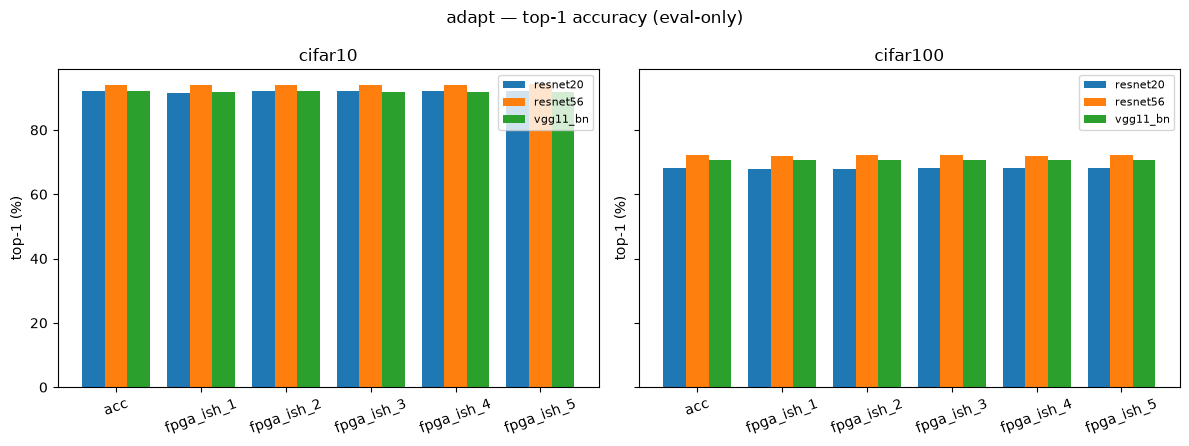

In [6]:
datasets = sorted(df.dataset.unique())
models   = sorted(df.model.unique())

fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.5), sharey=True)
if len(datasets) == 1:
    axes = [axes]

x = np.arange(len(MULTS_CHART))
w = 0.8 / max(len(models), 1)

for ax, ds in zip(axes, datasets):
    for i, m in enumerate(models):
        vals = [pivot.loc[(ds, m), mult] if (ds, m) in pivot.index else np.nan
                for mult in MULTS_CHART]
        ax.bar(x + i * w - 0.4 + w / 2, vals, width=w, label=m)
    ax.set_xticks(x); ax.set_xticklabels([m.replace("mul8s_", "") for m in MULTS_CHART], rotation=20)
    ax.set_title(ds)
    ax.set_ylabel("top-1 (%)")
    ax.legend(fontsize=8)

fig.suptitle(f"{FRAMEWORK} — top-1 accuracy (eval-only)")
fig.tight_layout()
fig.savefig(EXPORT_DIR / "top1_abs.png", dpi=120, bbox_inches="tight")

## Top-1 drop vs baseline

Same chart but rendered as `baseline_top1 - mult_top1`. The baseline column itself sits at zero, so the FPGA_ISH bars show the cost of each approximation.

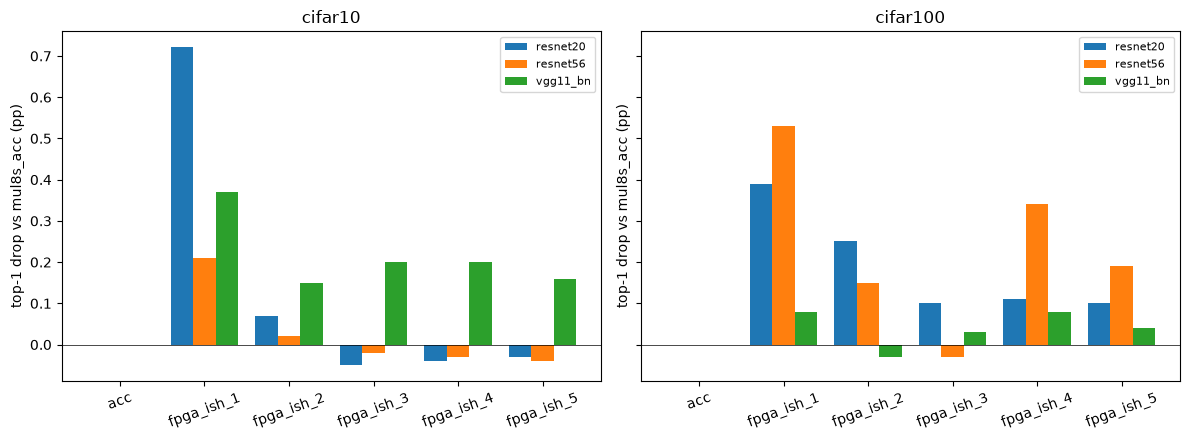

In [7]:
if BASELINE not in pivot.columns:
    print(f"{BASELINE} missing from CSV — drop chart skipped.")
else:
    drop = pivot.sub(pivot[BASELINE], axis=0).mul(-1)  # positive = degradation
    for ds, sub in drop.groupby(level="dataset"):
        d = EXPORTS / ds; d.mkdir(parents=True, exist_ok=True)
        sub.round(4).to_csv(d / "top1_drop.csv")

    fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 4.5), sharey=True)
    if len(datasets) == 1:
        axes = [axes]
    for ax, ds in zip(axes, datasets):
        for i, m in enumerate(models):
            vals = [drop.loc[(ds, m), mult] if (ds, m) in drop.index else np.nan
                    for mult in MULTS_CHART]
            ax.bar(x + i * w - 0.4 + w / 2, vals, width=w, label=m)
        ax.set_xticks(x); ax.set_xticklabels([m.replace("mul8s_", "") for m in MULTS_CHART], rotation=20)
        ax.set_title(ds)
        ax.set_ylabel(f"top-1 drop vs {BASELINE} (pp)")
        ax.axhline(0, color="k", lw=0.5)
        ax.legend(fontsize=8)
    # no figure title; the caption is added where the figure is embedded.
    fig.tight_layout()
    fig.savefig(EXPORT_DIR / "top1_drop.png", dpi=120, bbox_inches="tight")

## Retrained vs eval-only

For each multiplier, plot the eval-only top-1 and each retrained variant. The gap between bars shows how much accuracy retraining recovers. A large gap means the model can adapt to the approximation.

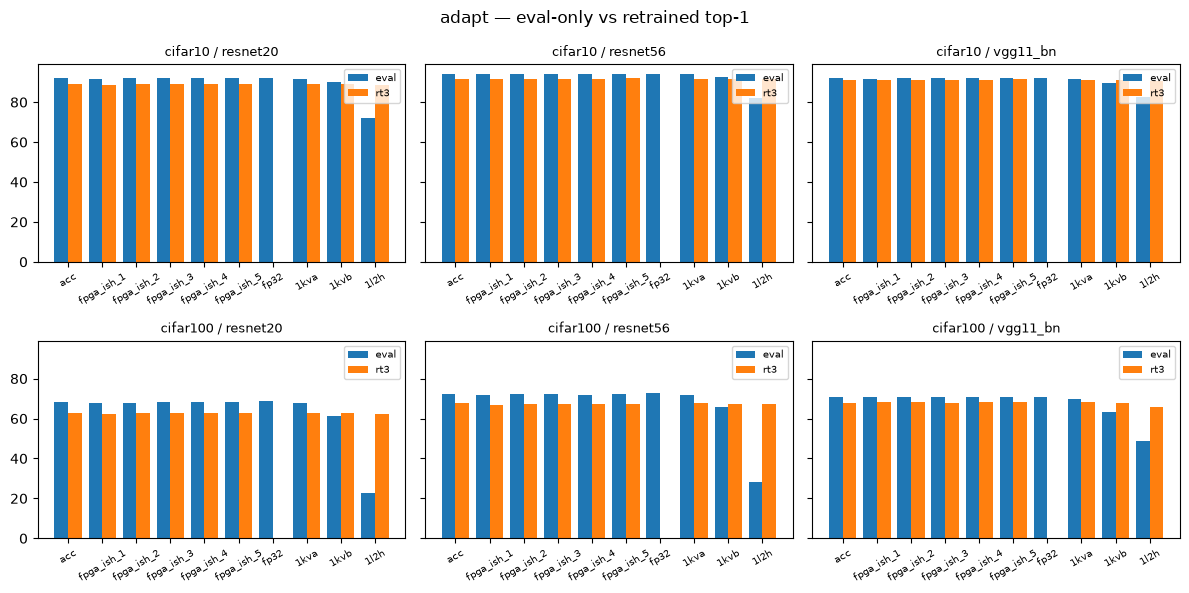

In [8]:
retrained_epochs_present = sorted({r for r in df.retrained_epochs.unique() if r > 0})
if not retrained_epochs_present:
    print("No retrained rows in CSV — retrain chart skipped.")
else:
    variants = [("eval", 0)] + [(f"rt{r}", r) for r in retrained_epochs_present]
    fig, axes = plt.subplots(len(datasets), len(models),
                              figsize=(4 * len(models), 3 * len(datasets)),
                              sharey=True, squeeze=False)
    xb = np.arange(len(MULTS))
    wb = 0.8 / len(variants)
    for r_idx, ds in enumerate(datasets):
        for c_idx, mdl in enumerate(models):
            ax = axes[r_idx][c_idx]
            for i, (lbl, rt) in enumerate(variants):
                vals = []
                for mult in MULTS:
                    row = df[(df.dataset == ds) & (df.model == mdl)
                              & (df.multiplier == mult) & (df.retrained_epochs == rt)]
                    vals.append(row.iloc[0]["top1"] if not row.empty else np.nan)
                ax.bar(xb + i * wb - 0.4 + wb / 2, vals, width=wb, label=lbl)
            ax.set_title(f"{ds} / {mdl}", fontsize=9)
            ax.set_xticks(xb); ax.set_xticklabels([m.replace("mul8s_", "") for m in MULTS],
                                                    rotation=30, fontsize=7)
            ax.legend(fontsize=7)
    fig.suptitle(f"{FRAMEWORK} — eval-only vs retrained top-1")
    fig.tight_layout()
    fig.savefig(EXPORT_DIR / "retrain_vs_eval.png", dpi=120, bbox_inches="tight")

## LUT-MAE vs accuracy drop

Sanity check on the implicit claim that lower LUT error → less accuracy drop. One point per (multiplier, dataset, model). Lines connect identical (dataset, model) cells to make the per-cell slope visible.

LUT-MAE is computed against `mul8s_exact` from `multipliers/luts/{FRAMEWORK}/`. If the headers aren't there (only the docker images have them), this cell skips.

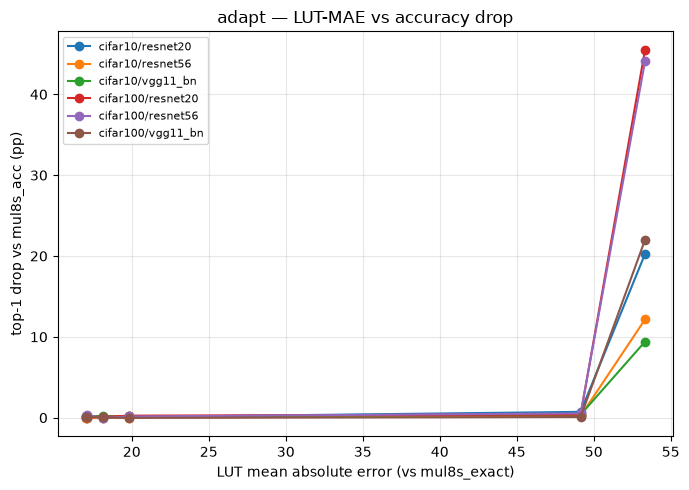

In [9]:
# LUT-MAE vs mul8s_exact, read from the built headers. docker/luts holds every
# multiplier (incl. python-only ones like 1l2h); fall back to the baked C dir.
LUT_DIR = next((p for p in [Path(f"/work/luts/{FRAMEWORK}"),
                            Path(f"../luts/{FRAMEWORK}"),
                            Path(f"/workspace/multipliers/luts/{FRAMEWORK}"),
                            Path(f"../../multipliers/luts/{FRAMEWORK}")]
                if (p / "mul8s_exact.h").exists()),
               Path(f"../luts/{FRAMEWORK}"))

def load_lut(name):
    text = (LUT_DIR / f"{name}.h").read_text()
    nums = re.findall(r"-?\d+", text.split("{", 1)[1])
    return np.array(nums, dtype=np.int16).reshape(256, 256)

def signed_view(lut):
    perm = np.r_[0:128, -128:0]
    order = np.argsort(perm)
    return lut[np.ix_(order, order)]

def lut_mae(name, ref):
    return float(np.abs(signed_view(load_lut(name)).astype(np.int32)
                         - signed_view(load_lut(ref)).astype(np.int32)).mean())

ref_name = "mul8s_exact" if (LUT_DIR / "mul8s_exact.h").exists() else None
if ref_name is None or not LUT_DIR.exists():
    print(f"LUT headers not found at {LUT_DIR} — scatter skipped.")
elif BASELINE not in pivot.columns:
    print(f"baseline {BASELINE} missing from CSV — scatter skipped.")
else:
    points = []
    # The EvoApprox anchors (1KVA/1KVB) are shown in the bias_vs_drop figure instead:
    # 1KVB is low-MAE but high-drop (its bias), which would muddy this MAE->drop view.
    # 1L2H (high MAE, high drop) stays in as the high-error reference.
    scatter_skip = {BASELINE, "mul8s_1kva", "mul8s_1kvb"}
    for mult in MULTS:
        if mult in scatter_skip:
            continue
        try:
            mae = lut_mae(mult, ref_name)
        except FileNotFoundError:
            continue
        for ds in datasets:
            for mdl in models:
                if (ds, mdl) not in drop.index or pd.isna(drop.loc[(ds, mdl), mult]):
                    continue
                points.append({"multiplier": mult, "dataset": ds, "model": mdl,
                                 "lut_mae": mae,
                                 "acc_drop_pp": drop.loc[(ds, mdl), mult]})
    if not points:
        print("no points to plot.")
    else:
        pts = pd.DataFrame(points)
        fig, ax = plt.subplots(figsize=(7, 5))
        for (ds, mdl), grp in pts.groupby(["dataset", "model"]):
            g = grp.sort_values("lut_mae")
            ax.plot(g["lut_mae"], g["acc_drop_pp"], marker="o", label=f"{ds}/{mdl}")
        ax.set_xlabel("LUT mean absolute error (vs mul8s_exact)")
        ax.set_ylabel(f"top-1 drop vs {BASELINE} (pp)")
        ax.set_title(f"{FRAMEWORK} — LUT-MAE vs accuracy drop")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
        fig.tight_layout()
        fig.savefig(EXPORT_DIR / "lut_mae_vs_drop.png", dpi=120, bbox_inches="tight")

In [ ]:
# Per-multiplier LUT-MAE-vs-drop SUMMARY exported for the paper. The scatter above is
# the in-notebook diagnostic; this is the compact table the paper embeds in its place. We
# keep only the FPGA_ISH variants -- 1l2h is the off-scale high-error reference that
# would dominate the table the same way it stretches the scatter's axes. CNN mean and
# worst are taken over the (dataset, model) cells, so the drop columns line up with
# arch_approx_drop.csv.
if "pts" in dir() and not pts.empty:
    ish = pts[pts.multiplier.str.contains("fpga_ish")]
    summ = (ish.groupby("multiplier")
               .agg(lut_mae=("lut_mae", "first"),
                    cnn_mean=("acc_drop_pp", "mean"),
                    cnn_worst=("acc_drop_pp", "max"))
               .reset_index())
    summ["multiplier"] = summ["multiplier"].str.replace("mul8s_fpga_ish_", "ISH-")
    summ["lut_mae"]   = summ["lut_mae"].round(1)
    summ["cnn_mean"]  = summ["cnn_mean"].round(3)
    summ["cnn_worst"] = summ["cnn_worst"].round(3)
    summ = summ.rename(columns={"multiplier": "Multiplier", "lut_mae": "LUT MAE (LSB)",
                                "cnn_mean": "CNN mean (pp)", "cnn_worst": "CNN worst (pp)"})
    summ = summ.sort_values("Multiplier").reset_index(drop=True)
    summ.to_csv(EXPORT_DIR / "lut_mae_vs_drop.csv", index=False)
    display(summ)
else:
    print("pts not available (scatter cell skipped) -- lut_mae_vs_drop.csv not written.")

## Bias vs MRE — the matched-MRE multiplier that still hurts

The LUT-MAE scatter above sorts the drop by absolute error, but relative error
(MRE) is the better predictor for the FPGA_ISH set. `mul8s_1kvb` is the awkward
case: its MRE (0.90 %) sits *inside* the FPGA_ISH band, so on MRE alone you'd
expect it to behave like `ish_2` — but eval-only it drops ~2 pp on CIFAR-10 and
~6–7 pp on CIFAR-100, while the in-band ISH designs barely move.

What separates them is the LUT **bias** (mean signed error). The FPGA_ISH
multipliers are zero-mean, so their per-MAC error cancels across a conv layer's
accumulation. `1kvb`/`1kva` are truncated array multipliers that under-shoot
*every* product, so the offset adds up coherently instead of cancelling — and it
bites hardest on CIFAR-100, where the margins are thinner. Panel (a) is the
break-away; panel (b) shows the drop lines up with |bias|, not MRE. (`1l2h` is
the separate high-MRE regime and is off-scale here.)

,multiplier,dataset,mre_pct,abs_bias,mean_drop_pp
0,ISH1,cifar10,1.329,0.00,0.434
1,ISH1,cifar100,1.329,0.00,0.334
2,ISH2,cifar10,0.806,0.00,0.080
3,ISH2,cifar100,0.806,0.00,0.124
4,ISH3,cifar10,0.722,0.00,0.043
5,ISH3,cifar100,0.722,0.00,0.033
6,ISH4,cifar10,0.655,0.00,0.043
7,ISH4,cifar100,0.655,0.00,0.177
8,ISH5,cifar10,0.643,0.00,0.030
9,ISH5,cifar100,0.643,0.00,0.110


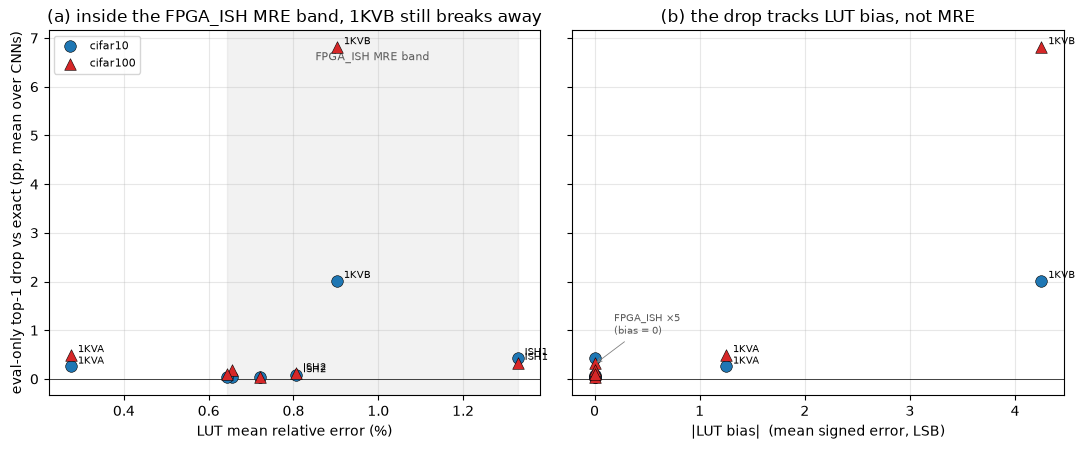

In [10]:
# Bias vs MRE: why a matched-MRE multiplier can still hurt. Reuses load_lut /
# signed_view from the LUT-MAE scatter cell above; drop/pivot/MULTS from earlier.
_ii, _jj = np.meshgrid(np.r_[-128:128], np.r_[-128:128], indexing="ij")
_EXACT = _ii * _jj
_nz = _EXACT != 0
_REF = signed_view(load_lut("mul8s_exact")).astype(np.int32)

def lut_bias_mre(name):
    """LUT bias (mean signed error vs exact) and MRE% over non-zero products."""
    L = signed_view(load_lut(name)).astype(np.int32)
    err = L - _REF
    return float(err.mean()), float((np.abs(err[_nz]) / np.abs(_EXACT[_nz])).mean()) * 100

# Low-MRE regime only: FPGA_ISH + the two EvoApprox anchors. 1L2H is the separate
# high-MRE regime (drop 9-45 pp) -- off-scale here, kept to the bar/scatter charts.
LOWMRE = [m for m in MULTS if "fpga_ish" in m or m in ("mul8s_1kva", "mul8s_1kvb")]
_short = {m: m.replace("mul8s_", "").replace("fpga_ish_", "ISH").upper() for m in LOWMRE}
_ds = [d for d in ["cifar10", "cifar100"] if d in drop.index.get_level_values("dataset")]

bias_rows = []
for m in LOWMRE:
    try:
        b, mre = lut_bias_mre(m)
    except FileNotFoundError:
        continue
    for ds in _ds:
        vals = [drop.loc[(ds, mdl), m] for mdl in drop.loc[ds].index
                if not pd.isna(drop.loc[(ds, mdl), m])]
        if vals:
            bias_rows.append({"multiplier": _short[m], "dataset": ds, "mre_pct": mre,
                              "abs_bias": abs(b), "mean_drop_pp": float(np.mean(vals))})
S = pd.DataFrame(bias_rows)
S.round(4).to_csv(EXPORT_DIR / "bias_vs_drop.csv", index=False)

if not S.empty and S["abs_bias"].nunique() > 1:
    _band = (S[S.multiplier.str.startswith("ISH")]["mre_pct"].min(),
             S[S.multiplier.str.startswith("ISH")]["mre_pct"].max())
    _sty = {"cifar10": ("tab:blue", "o"), "cifar100": ("tab:red", "^")}
    _lab = {"mre_pct": {"1KVB", "1KVA", "ISH1", "ISH2"}, "abs_bias": {"1KVB", "1KVA"}}
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    for ax, (xc, xl) in zip(axes, [("mre_pct", "LUT mean relative error (%)"),
                                   ("abs_bias", "|LUT bias|  (mean signed error, LSB)")]):
        if xc == "mre_pct":
            ax.axvspan(*_band, color="0.6", alpha=0.12, zorder=0)
            ax.text(np.mean(_band), S["mean_drop_pp"].max() * 0.96, "FPGA_ISH MRE band",
                    ha="center", fontsize=8, color="0.35")
        for ds, (c, mk) in _sty.items():
            g = S[S.dataset == ds]
            if g.empty:
                continue
            ax.scatter(g[xc], g["mean_drop_pp"], c=c, marker=mk, s=70, label=ds,
                       edgecolor="k", linewidth=0.4, zorder=3)
            for _, r in g.iterrows():
                if r["multiplier"] in _lab[xc]:
                    ax.annotate(r["multiplier"], (r[xc], r["mean_drop_pp"]), fontsize=7.5,
                                xytext=(5, 2), textcoords="offset points")
        if xc == "abs_bias":
            ax.annotate("FPGA_ISH ×5\n(bias = 0)", (0, 0.3), fontsize=7.5,
                        xytext=(14, 22), textcoords="offset points", color="0.35",
                        arrowprops=dict(arrowstyle="->", color="0.5", lw=0.6))
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel(xl)
        ax.grid(alpha=0.3, zorder=0)
    axes[0].set_ylabel("eval-only top-1 drop vs exact (pp, mean over CNNs)")
    axes[0].set_title("(a) inside the FPGA_ISH MRE band, 1KVB still breaks away")
    axes[1].set_title("(b) the drop tracks LUT bias, not MRE")
    axes[0].legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    fig.savefig(EXPORT_DIR / "bias_vs_drop.png", dpi=120, bbox_inches="tight")
S.round(3)


In [ ]:
# Wide per-multiplier table behind the bias-vs-MRE point, exported for the paper
# in place of the two-panel scatter above.
# Pivots the long bias rows (S) into one row per multiplier: MRE and |bias| (both
# dataset-invariant) next to the per-dataset CNN-mean drop. FPGA_ISH first, then the
# two EvoApprox anchors, matching the figure's set. Drop headers are kept short
# ("CIFAR-10 (pp)") so the 5-column table doesn't overflow a paper column.
if "S" in dir() and not S.empty:
    wide = S.pivot_table(index="multiplier", columns="dataset", values="mean_drop_pp")
    meta = S.groupby("multiplier")[["mre_pct", "abs_bias"]].first()
    tbl = meta.join(wide).reset_index()
    order = {k: i for i, k in enumerate(["ISH1", "ISH2", "ISH3", "ISH4", "ISH5",
                                         "1KVA", "1KVB"])}
    tbl = tbl.sort_values("multiplier", key=lambda s: s.map(order)).reset_index(drop=True)
    tbl["multiplier"] = tbl["multiplier"].str.replace(r"^ISH(\d)$", r"ISH-\1", regex=True)
    tbl["mre_pct"]  = tbl["mre_pct"].round(2)
    tbl["abs_bias"] = tbl["abs_bias"].round(2)
    for ds in ["cifar10", "cifar100"]:
        if ds in tbl.columns:
            tbl[ds] = tbl[ds].round(3)
    tbl = tbl.rename(columns={"multiplier": "Multiplier", "mre_pct": "MRE (%)",
                              "abs_bias": "|bias| (LSB)",
                              "cifar10": "CIFAR-10 (pp)",
                              "cifar100": "CIFAR-100 (pp)"})
    cols = ["Multiplier", "MRE (%)", "|bias| (LSB)",
            "CIFAR-10 (pp)", "CIFAR-100 (pp)"]
    tbl = tbl[[c for c in cols if c in tbl.columns]]
    tbl.to_csv(EXPORT_DIR / "bias_vs_drop_table.csv", index=False)
    display(tbl)
else:
    print("S not available (bias cell skipped) -- bias_vs_drop_table.csv not written.")

## Saved exports

Everything written to `results/<framework>/exports/` by this run -- per-dataset accuracy tables (CSV) and the figures above (PNG).

In [11]:
print(f"Exports under: {EXPORTS.resolve()}\n")
for p in sorted(EXPORTS.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(EXPORTS))
print("\nOpen the results CSV:")
display(FileLink(str(CSV_PATH)))

Exports under: /work/results/adapt/exports

   _combined/bias_vs_drop.csv
   _combined/bias_vs_drop.png
   _combined/lut_mae_vs_drop.png
   _combined/retrain_vs_eval.png
   _combined/top1_abs.png
   _combined/top1_drop.png
   _combined/top1_eval_body.csv
   cifar10/deepdive_mul8s_fpga_ish_3.csv
   cifar10/top1_drop.csv
   cifar10/top1_eval.csv
   cifar10/top1_retrain.csv
   cifar100/deepdive_mul8s_fpga_ish_3.csv
   cifar100/top1_drop.csv
   cifar100/top1_eval.csv
   cifar100/top1_retrain.csv
   deepdive_mul8s_fpga_ish_3_drop.png

Open the results CSV:


/work/results/adapt/runs.csv